In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torchvision.models import DenseNet121_Weights
from torch.utils.data import DataLoader
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score, top_k_accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [ ]:
data_dir = 'new_dataset'  # train/ val/ test/ folders inside
batch_size = 64

data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.RandomRotation(30),
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
        transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.9, 1.1), shear=10),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ]),
}

image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), transform=data_transforms[x])
                  for x in ['train', 'val', 'test']}

dataloaders = {x: DataLoader(image_datasets[x], batch_size=batch_size, shuffle=(x == 'train'))
               for x in ['train', 'val', 'test']}

class_names = image_datasets['train'].classes
num_classes = len(class_names)
print(f"Detected {num_classes} classes.")


Detected 20 classes.


In [ ]:
weights = DenseNet121_Weights.DEFAULT
model = models.densenet121(weights=weights)
model.classifier = nn.Linear(model.classifier.in_features, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)  # L2 regularization


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth
100%|██████████| 30.8M/30.8M [00:00<00:00, 221MB/s]


In [ ]:
def train_model(model, dataloaders, criterion, optimizer, num_epochs=20, patience=5):
    history = {k: [] for k in [
        'train_loss', 'val_loss', 'train_acc', 'val_acc',
        'train_precision', 'val_precision',
        'train_recall', 'val_recall',
        'train_f1', 'val_f1',
        'val_top5'
    ]}

    best_val_acc = 0.0
    best_model_wts = model.state_dict()
    no_improve = 0

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch + 1}/{num_epochs}\n" + "-" * 30)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0
            all_preds = []
            all_labels = []
            all_probs = []

            dataloader = tqdm(dataloaders[phase], desc=phase, leave=False)
            for inputs, labels in dataloader:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    probs = nn.functional.softmax(outputs, dim=1)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
                all_probs.extend(probs.detach().cpu().numpy())

                dataloader.set_postfix(loss=loss.item())

            epoch_loss = running_loss / len(dataloaders[phase].dataset)
            epoch_acc = running_corrects.double() / len(dataloaders[phase].dataset)
            epoch_precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
            epoch_recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
            epoch_f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)

            print(f"{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f} "
                  f"Precision: {epoch_precision:.4f} Recall: {epoch_recall:.4f} F1: {epoch_f1:.4f}")

            if phase == 'val':
                top5 = top_k_accuracy_score(all_labels, all_probs, k=5)
                print(f"Top-5 Accuracy: {top5:.4f}")
                history['val_top5'].append(top5)

                # Classification report & confusion matrix
                print("\nClassification Report (Val):")
                print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))

                cm = confusion_matrix(all_labels, all_preds)
                plt.figure(figsize=(10, 8))
                sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                            xticklabels=class_names, yticklabels=class_names)
                plt.title(f'Confusion Matrix - Epoch {epoch+1}')
                plt.xlabel('Predicted')
                plt.ylabel('True')
                plt.xticks(rotation=45, ha='right')
                plt.yticks(rotation=0)
                plt.show()

                # Save best model
                if epoch_acc > best_val_acc:
                    best_val_acc = epoch_acc
                    best_model_wts = model.state_dict()
                    no_improve = 0
                    torch.save(model.state_dict(), 'best_densenet121.pth')
                else:
                    no_improve += 1
                    if no_improve >= patience:
                        print("⏹️ Early stopping triggered.")
                        model.load_state_dict(best_model_wts)
                        return model, history

            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc.item())
            history[f'{phase}_precision'].append(epoch_precision)
            history[f'{phase}_recall'].append(epoch_recall)
            history[f'{phase}_f1'].append(epoch_f1)

    model.load_state_dict(best_model_wts)
    return model, history



Epoch 1/50
------------------------------


Train Loss: 1.5975 Acc: 0.5357 Precision: 0.5312 Recall: 0.5356 F1: 0.5280


Val Loss: 0.8984 Acc: 0.7337 Precision: 0.7522 Recall: 0.7337 F1: 0.7293
Top-5 Accuracy: 0.9384

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.72      0.62      0.67       400
            Ageratum conyzoides       0.69      0.33      0.44       400
          Ageratum houstonianum       0.83      0.53      0.65       400
    Alternanthera philoxeroides       0.52      0.91      0.66       400
            Amaranthus spinosus       0.89      0.61      0.73       400
              Argemone mexicana       0.95      0.92      0.93       399
                  Bidens Pilosa       0.57      0.66      0.61       397
            Chromolaena odorata       0.53      0.57      0.55       398
           Eichhornia crassipes       0.81      0.89      0.85       398
         Erigeron karvinskianus       0.80      0.82      0.81       400
Ipomoea carnea subsp. fistulosa       0.74      0.80      0.77       3

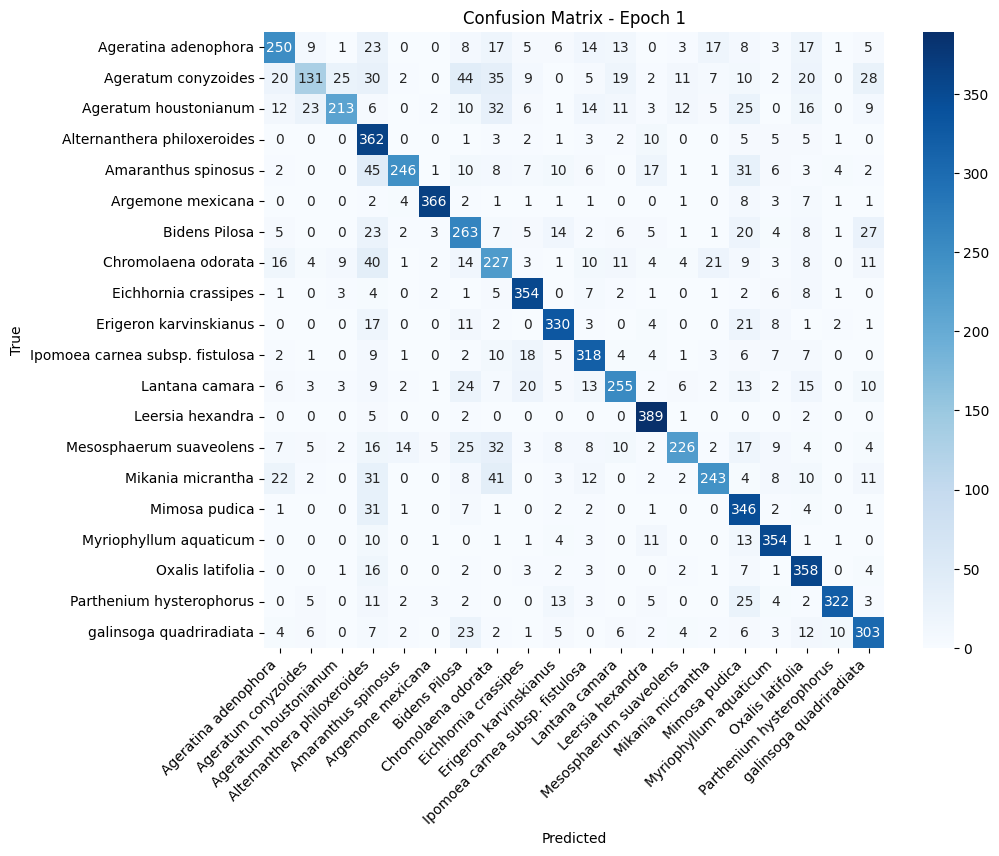


Epoch 2/50
------------------------------


Train Loss: 0.9744 Acc: 0.7100 Precision: 0.7065 Recall: 0.7099 F1: 0.7069


Val Loss: 0.6894 Acc: 0.7888 Precision: 0.7952 Recall: 0.7887 F1: 0.7851
Top-5 Accuracy: 0.9615

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.80      0.69      0.74       400
            Ageratum conyzoides       0.57      0.55      0.56       400
          Ageratum houstonianum       0.76      0.56      0.64       400
    Alternanthera philoxeroides       0.62      0.90      0.73       400
            Amaranthus spinosus       0.86      0.77      0.81       400
              Argemone mexicana       0.95      0.91      0.93       399
                  Bidens Pilosa       0.70      0.65      0.68       397
            Chromolaena odorata       0.86      0.48      0.62       398
           Eichhornia crassipes       0.96      0.90      0.93       398
         Erigeron karvinskianus       0.84      0.90      0.87       400
Ipomoea carnea subsp. fistulosa       0.70      0.88      0.78       3

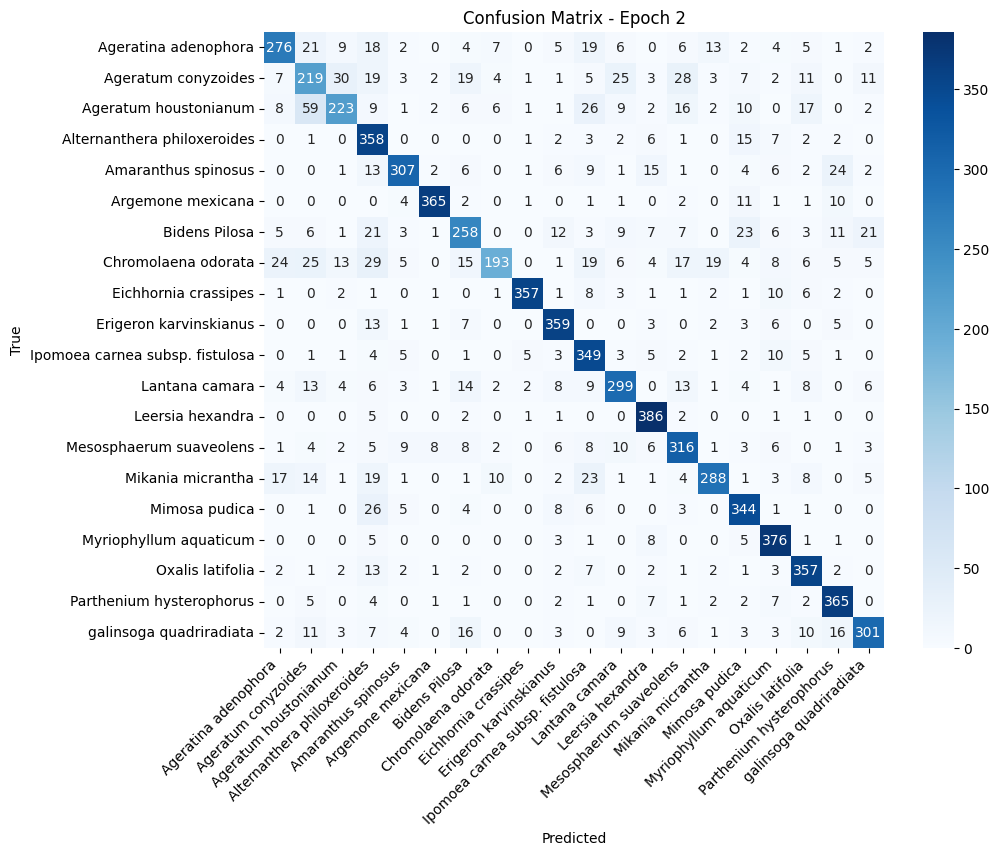


Epoch 3/50
------------------------------


Train Loss: 0.8244 Acc: 0.7508 Precision: 0.7480 Recall: 0.7507 F1: 0.7485


Val Loss: 0.6097 Acc: 0.8148 Precision: 0.8260 Recall: 0.8148 F1: 0.8160
Top-5 Accuracy: 0.9668

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.76      0.80      0.78       400
            Ageratum conyzoides       0.51      0.67      0.58       400
          Ageratum houstonianum       0.82      0.66      0.73       400
    Alternanthera philoxeroides       0.77      0.89      0.82       400
            Amaranthus spinosus       0.96      0.78      0.86       400
              Argemone mexicana       0.97      0.93      0.95       399
                  Bidens Pilosa       0.73      0.69      0.71       397
            Chromolaena odorata       0.72      0.72      0.72       398
           Eichhornia crassipes       0.96      0.92      0.94       398
         Erigeron karvinskianus       0.82      0.85      0.84       400
Ipomoea carnea subsp. fistulosa       0.87      0.82      0.84       3

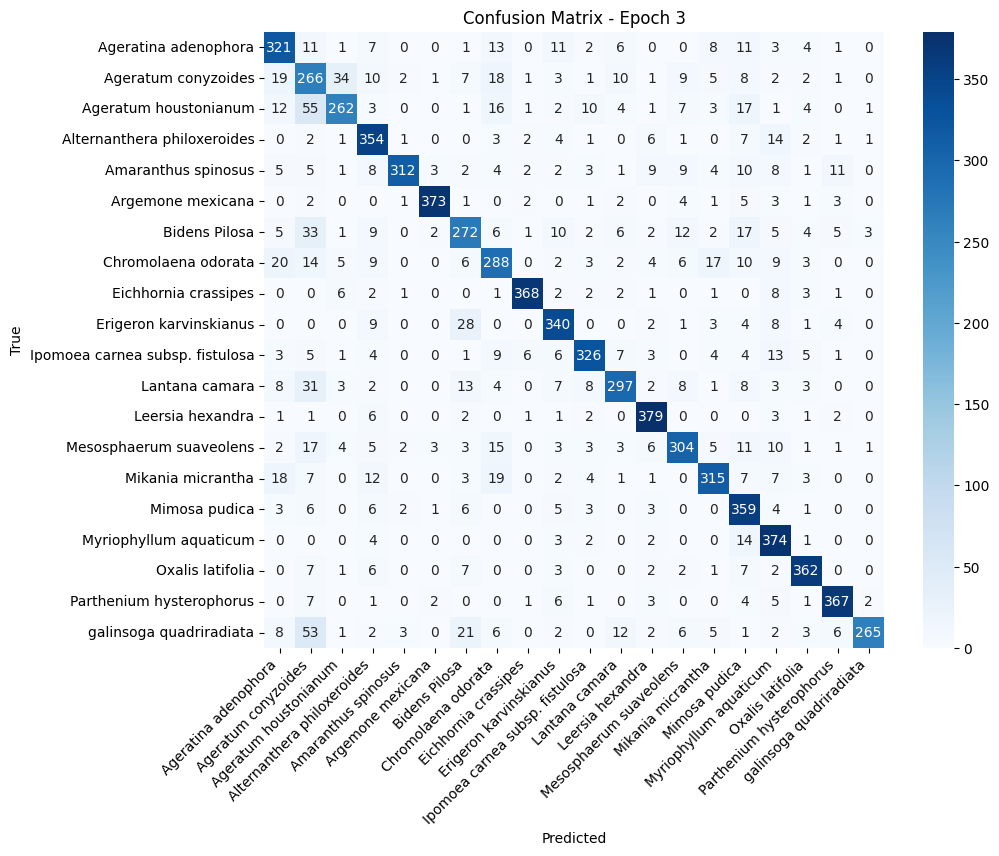


Epoch 4/50
------------------------------


Train Loss: 0.7442 Acc: 0.7730 Precision: 0.7709 Recall: 0.7730 F1: 0.7713


Val Loss: 0.5527 Acc: 0.8300 Precision: 0.8351 Recall: 0.8300 F1: 0.8283
Top-5 Accuracy: 0.9738

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.73      0.85      0.79       400
            Ageratum conyzoides       0.76      0.53      0.62       400
          Ageratum houstonianum       0.79      0.69      0.74       400
    Alternanthera philoxeroides       0.85      0.88      0.86       400
            Amaranthus spinosus       0.96      0.80      0.87       400
              Argemone mexicana       0.97      0.95      0.96       399
                  Bidens Pilosa       0.76      0.71      0.73       397
            Chromolaena odorata       0.63      0.78      0.70       398
           Eichhornia crassipes       0.87      0.94      0.90       398
         Erigeron karvinskianus       0.88      0.90      0.89       400
Ipomoea carnea subsp. fistulosa       0.82      0.87      0.84       3

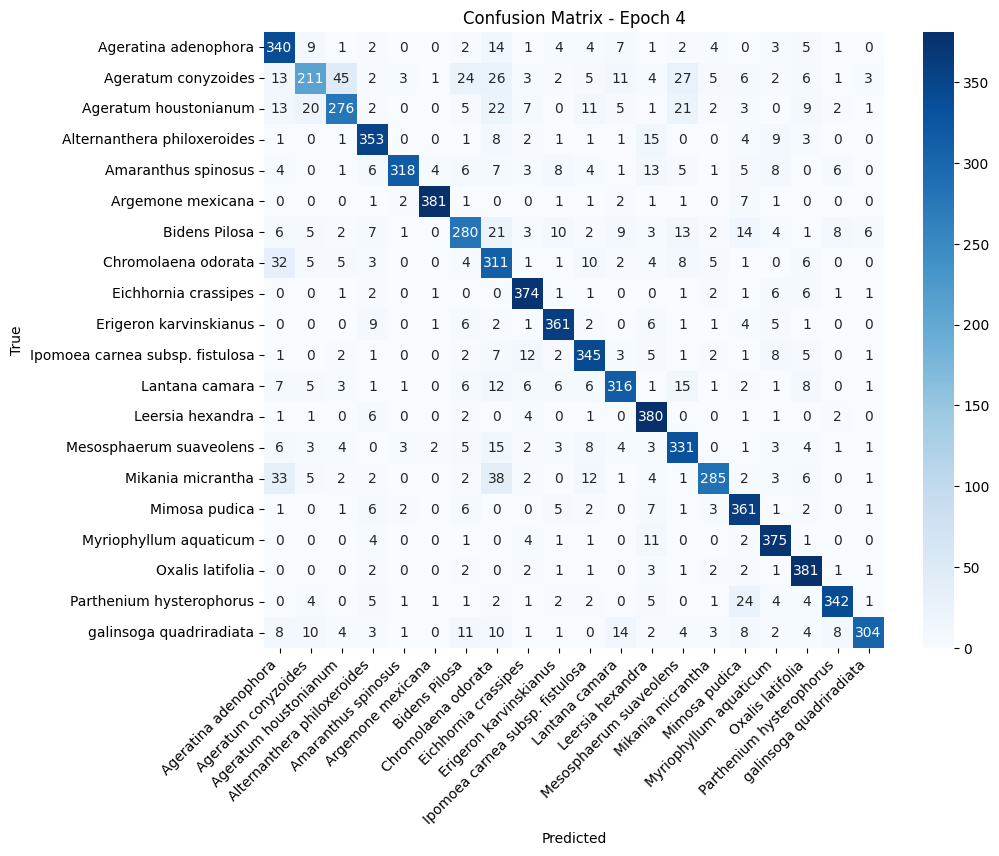


Epoch 5/50
------------------------------


Train Loss: 0.6902 Acc: 0.7884 Precision: 0.7862 Recall: 0.7883 F1: 0.7868


Val Loss: 0.4764 Acc: 0.8530 Precision: 0.8596 Recall: 0.8530 F1: 0.8518
Top-5 Accuracy: 0.9780

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.73      0.89      0.80       400
            Ageratum conyzoides       0.78      0.48      0.60       400
          Ageratum houstonianum       0.80      0.77      0.79       400
    Alternanthera philoxeroides       0.90      0.89      0.89       400
            Amaranthus spinosus       0.93      0.87      0.90       400
              Argemone mexicana       0.99      0.96      0.97       399
                  Bidens Pilosa       0.63      0.83      0.72       397
            Chromolaena odorata       0.74      0.76      0.75       398
           Eichhornia crassipes       0.97      0.92      0.94       398
         Erigeron karvinskianus       0.89      0.92      0.90       400
Ipomoea carnea subsp. fistulosa       0.86      0.87      0.87       3

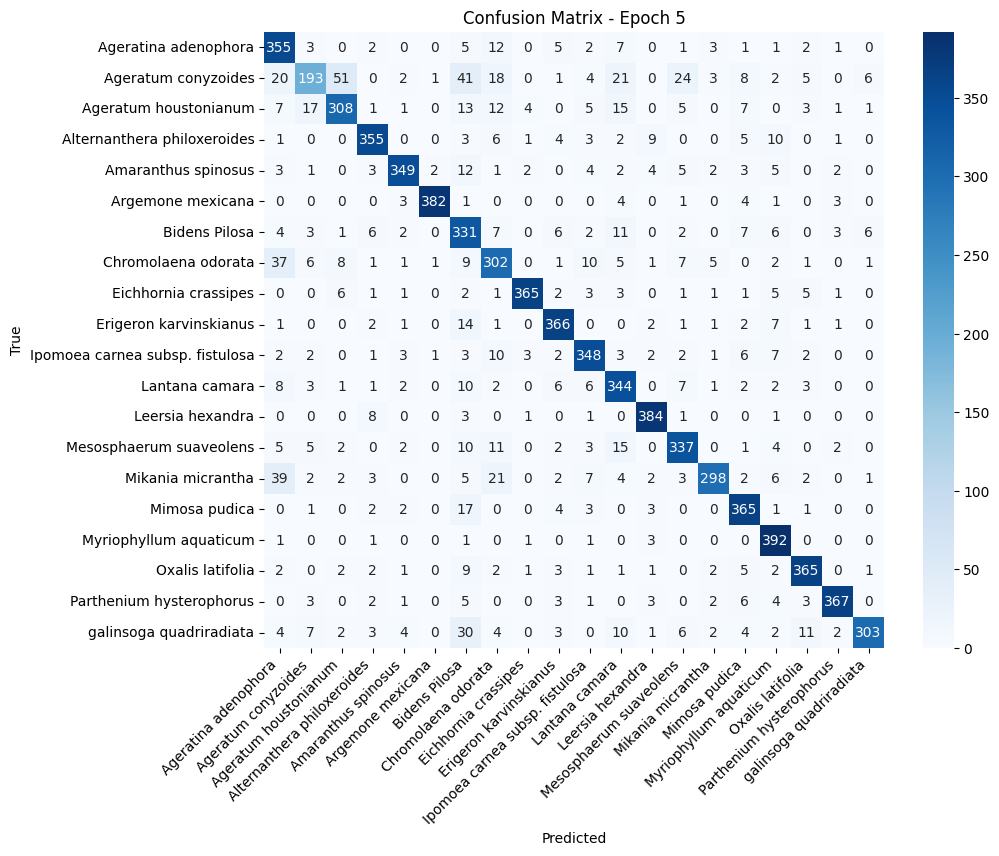


Epoch 6/50
------------------------------


Train Loss: 0.6469 Acc: 0.8015 Precision: 0.7999 Recall: 0.8014 F1: 0.8003


Val Loss: 0.4852 Acc: 0.8519 Precision: 0.8541 Recall: 0.8519 F1: 0.8510
Top-5 Accuracy: 0.9763

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.86      0.84      0.85       400
            Ageratum conyzoides       0.71      0.68      0.70       400
          Ageratum houstonianum       0.82      0.75      0.78       400
    Alternanthera philoxeroides       0.77      0.90      0.83       400
            Amaranthus spinosus       0.95      0.82      0.88       400
              Argemone mexicana       0.98      0.94      0.96       399
                  Bidens Pilosa       0.74      0.71      0.72       397
            Chromolaena odorata       0.80      0.72      0.76       398
           Eichhornia crassipes       0.95      0.93      0.94       398
         Erigeron karvinskianus       0.86      0.91      0.89       400
Ipomoea carnea subsp. fistulosa       0.89      0.85      0.87       3

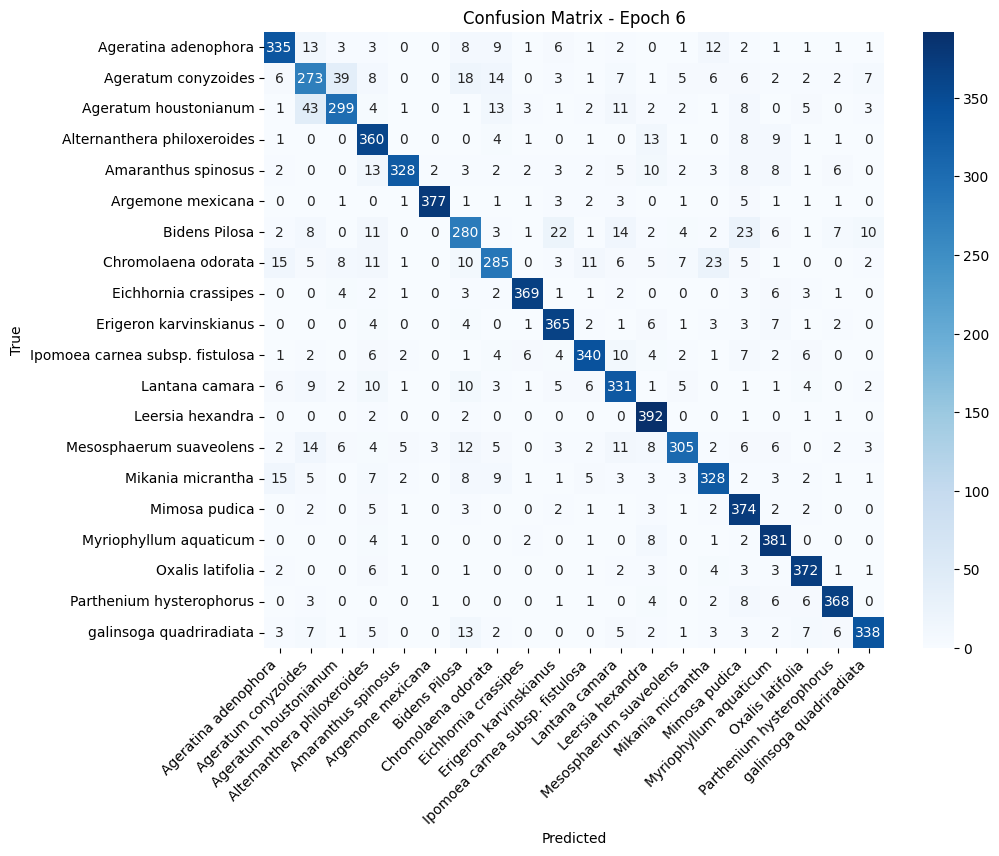


Epoch 7/50
------------------------------


Train Loss: 0.6081 Acc: 0.8114 Precision: 0.8103 Recall: 0.8113 F1: 0.8105


Val Loss: 0.4844 Acc: 0.8505 Precision: 0.8542 Recall: 0.8505 F1: 0.8494
Top-5 Accuracy: 0.9771

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.79      0.89      0.83       400
            Ageratum conyzoides       0.74      0.57      0.64       400
          Ageratum houstonianum       0.79      0.76      0.77       400
    Alternanthera philoxeroides       0.79      0.92      0.85       400
            Amaranthus spinosus       0.88      0.89      0.89       400
              Argemone mexicana       0.99      0.93      0.96       399
                  Bidens Pilosa       0.68      0.78      0.73       397
            Chromolaena odorata       0.74      0.74      0.74       398
           Eichhornia crassipes       0.93      0.94      0.93       398
         Erigeron karvinskianus       0.93      0.93      0.93       400
Ipomoea carnea subsp. fistulosa       0.93      0.83      0.87       3

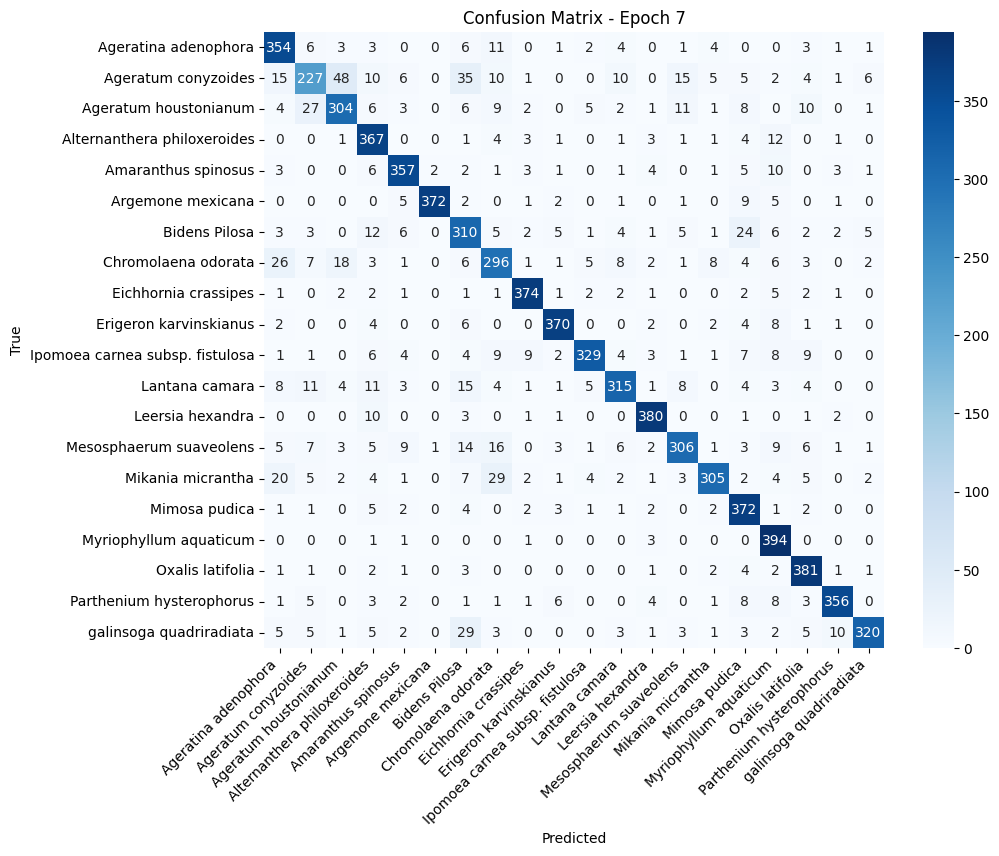


Epoch 8/50
------------------------------


Train Loss: 0.5741 Acc: 0.8216 Precision: 0.8203 Recall: 0.8216 F1: 0.8206


Val Loss: 0.4531 Acc: 0.8641 Precision: 0.8663 Recall: 0.8640 F1: 0.8625
Top-5 Accuracy: 0.9776

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.75      0.88      0.81       400
            Ageratum conyzoides       0.78      0.63      0.70       400
          Ageratum houstonianum       0.80      0.81      0.80       400
    Alternanthera philoxeroides       0.80      0.93      0.86       400
            Amaranthus spinosus       0.93      0.83      0.88       400
              Argemone mexicana       0.98      0.95      0.96       399
                  Bidens Pilosa       0.89      0.71      0.79       397
            Chromolaena odorata       0.81      0.71      0.76       398
           Eichhornia crassipes       0.92      0.93      0.93       398
         Erigeron karvinskianus       0.87      0.94      0.90       400
Ipomoea carnea subsp. fistulosa       0.83      0.87      0.85       3

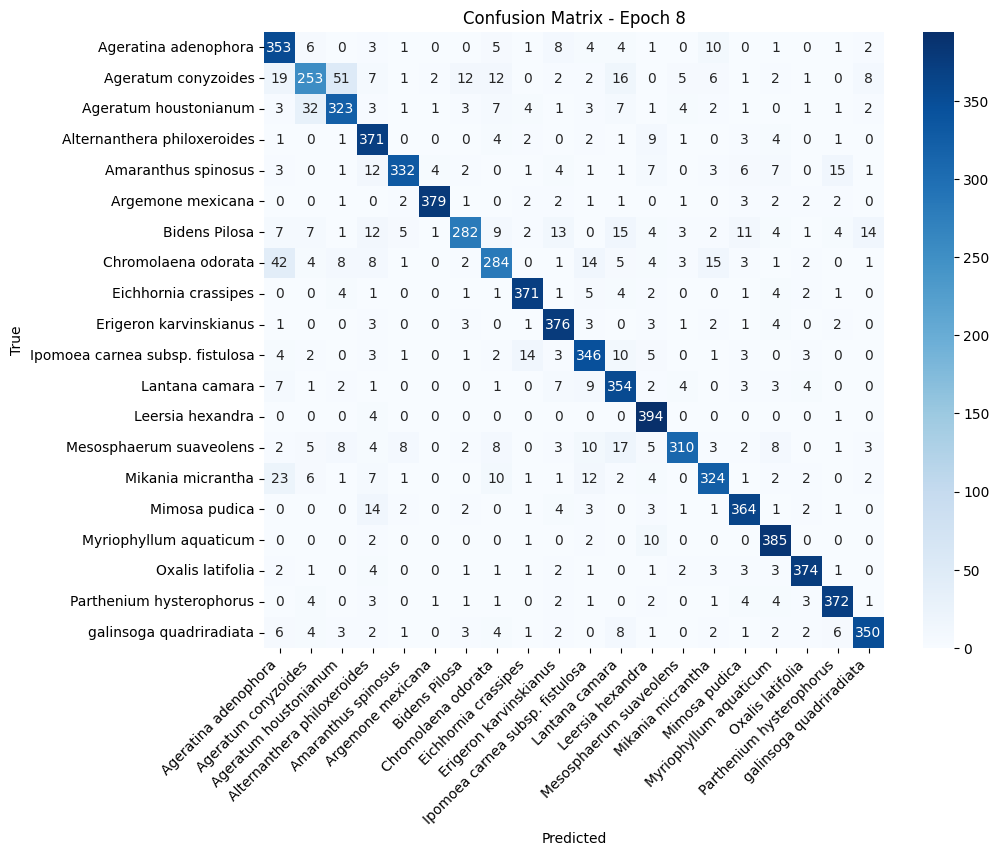


Epoch 9/50
------------------------------


Train Loss: 0.5626 Acc: 0.8260 Precision: 0.8248 Recall: 0.8259 F1: 0.8250


Val Loss: 0.4787 Acc: 0.8517 Precision: 0.8597 Recall: 0.8516 F1: 0.8520
Top-5 Accuracy: 0.9742

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.80      0.85      0.82       400
            Ageratum conyzoides       0.68      0.71      0.70       400
          Ageratum houstonianum       0.78      0.79      0.78       400
    Alternanthera philoxeroides       0.68      0.94      0.79       400
            Amaranthus spinosus       0.95      0.80      0.87       400
              Argemone mexicana       0.97      0.95      0.96       399
                  Bidens Pilosa       0.80      0.79      0.80       397
            Chromolaena odorata       0.75      0.75      0.75       398
           Eichhornia crassipes       0.96      0.92      0.94       398
         Erigeron karvinskianus       0.89      0.92      0.91       400
Ipomoea carnea subsp. fistulosa       0.93      0.83      0.88       3

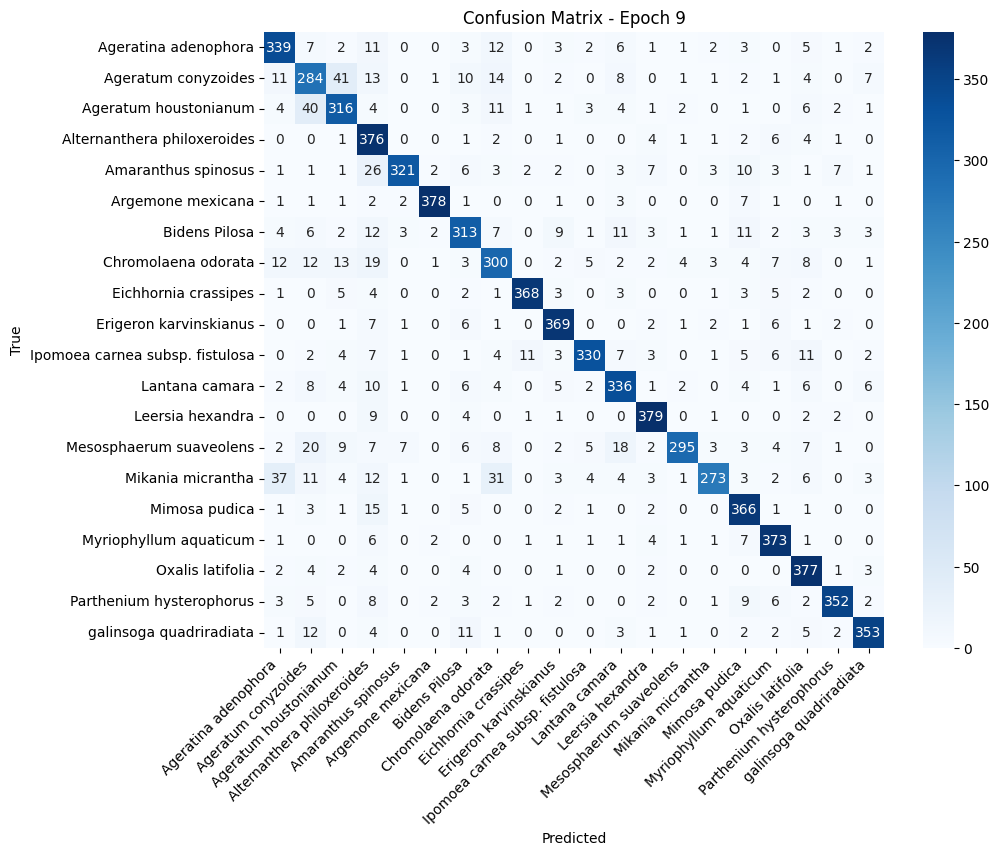


Epoch 10/50
------------------------------


Train Loss: 0.5392 Acc: 0.8334 Precision: 0.8325 Recall: 0.8333 F1: 0.8326


Val Loss: 0.4053 Acc: 0.8735 Precision: 0.8756 Recall: 0.8734 F1: 0.8727
Top-5 Accuracy: 0.9826

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.81      0.88      0.85       400
            Ageratum conyzoides       0.79      0.64      0.70       400
          Ageratum houstonianum       0.81      0.80      0.81       400
    Alternanthera philoxeroides       0.83      0.91      0.87       400
            Amaranthus spinosus       0.87      0.89      0.88       400
              Argemone mexicana       0.98      0.94      0.96       399
                  Bidens Pilosa       0.81      0.81      0.81       397
            Chromolaena odorata       0.71      0.83      0.77       398
           Eichhornia crassipes       0.96      0.94      0.95       398
         Erigeron karvinskianus       0.94      0.92      0.93       400
Ipomoea carnea subsp. fistulosa       0.86      0.92      0.89       3

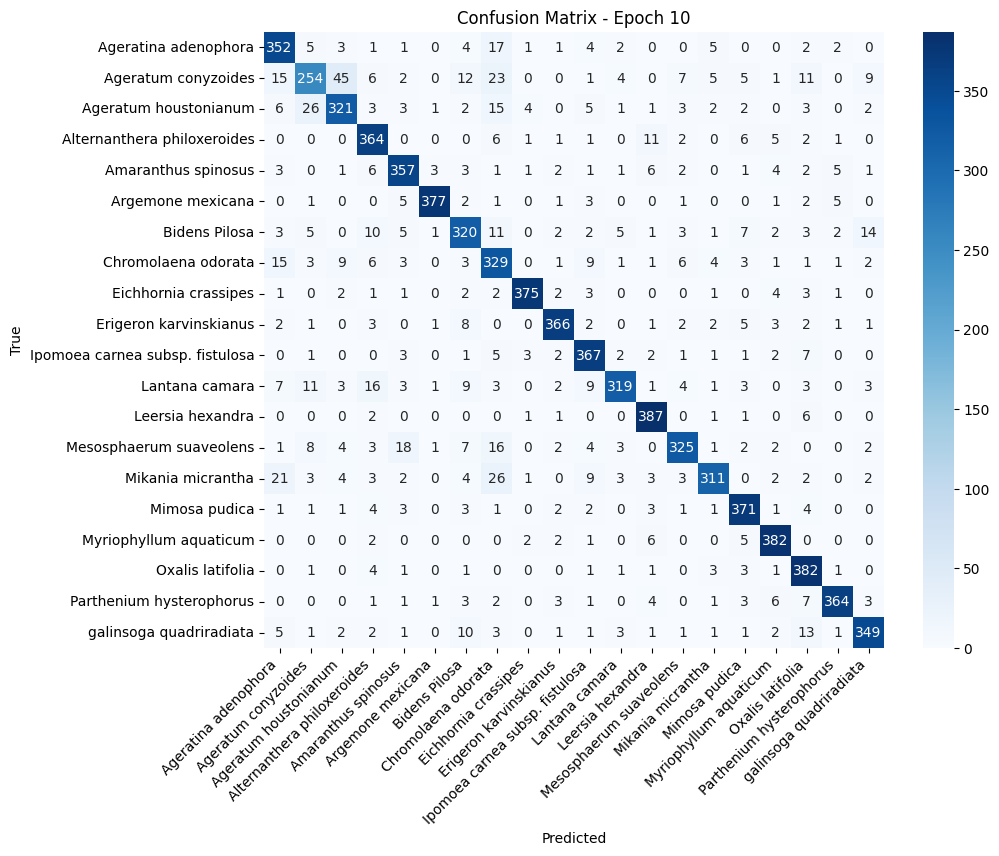


Epoch 11/50
------------------------------


Train Loss: 0.5251 Acc: 0.8345 Precision: 0.8334 Recall: 0.8345 F1: 0.8338


Val Loss: 0.4058 Acc: 0.8762 Precision: 0.8799 Recall: 0.8762 F1: 0.8765
Top-5 Accuracy: 0.9803

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.88      0.83      0.85       400
            Ageratum conyzoides       0.70      0.72      0.71       400
          Ageratum houstonianum       0.80      0.82      0.81       400
    Alternanthera philoxeroides       0.91      0.90      0.91       400
            Amaranthus spinosus       0.96      0.86      0.90       400
              Argemone mexicana       0.99      0.94      0.96       399
                  Bidens Pilosa       0.79      0.84      0.82       397
            Chromolaena odorata       0.79      0.72      0.75       398
           Eichhornia crassipes       0.94      0.95      0.95       398
         Erigeron karvinskianus       0.96      0.88      0.92       400
Ipomoea carnea subsp. fistulosa       0.86      0.92      0.89       3

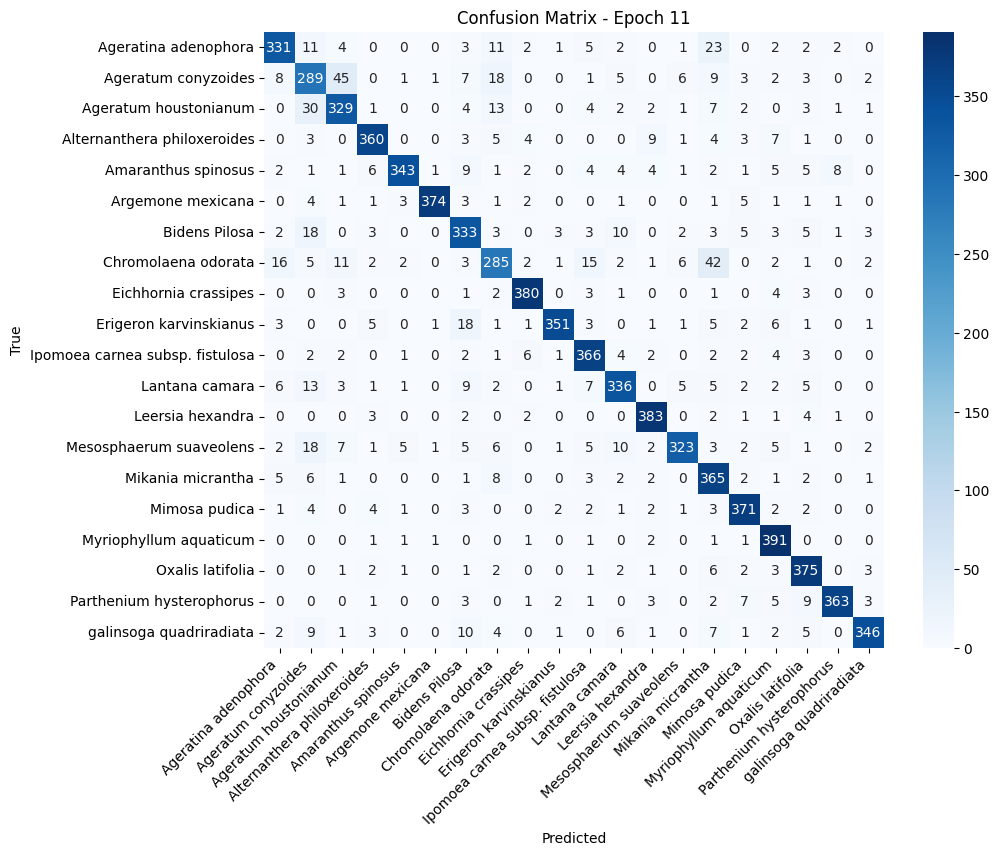


Epoch 12/50
------------------------------


Train Loss: 0.5099 Acc: 0.8438 Precision: 0.8427 Recall: 0.8437 F1: 0.8430


Val Loss: 0.4368 Acc: 0.8666 Precision: 0.8730 Recall: 0.8666 F1: 0.8667
Top-5 Accuracy: 0.9783

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.93      0.78      0.85       400
            Ageratum conyzoides       0.77      0.65      0.71       400
          Ageratum houstonianum       0.81      0.83      0.82       400
    Alternanthera philoxeroides       0.70      0.94      0.81       400
            Amaranthus spinosus       0.91      0.86      0.88       400
              Argemone mexicana       0.99      0.92      0.95       399
                  Bidens Pilosa       0.75      0.84      0.79       397
            Chromolaena odorata       0.72      0.77      0.75       398
           Eichhornia crassipes       0.92      0.95      0.93       398
         Erigeron karvinskianus       0.95      0.90      0.92       400
Ipomoea carnea subsp. fistulosa       0.95      0.86      0.90       3

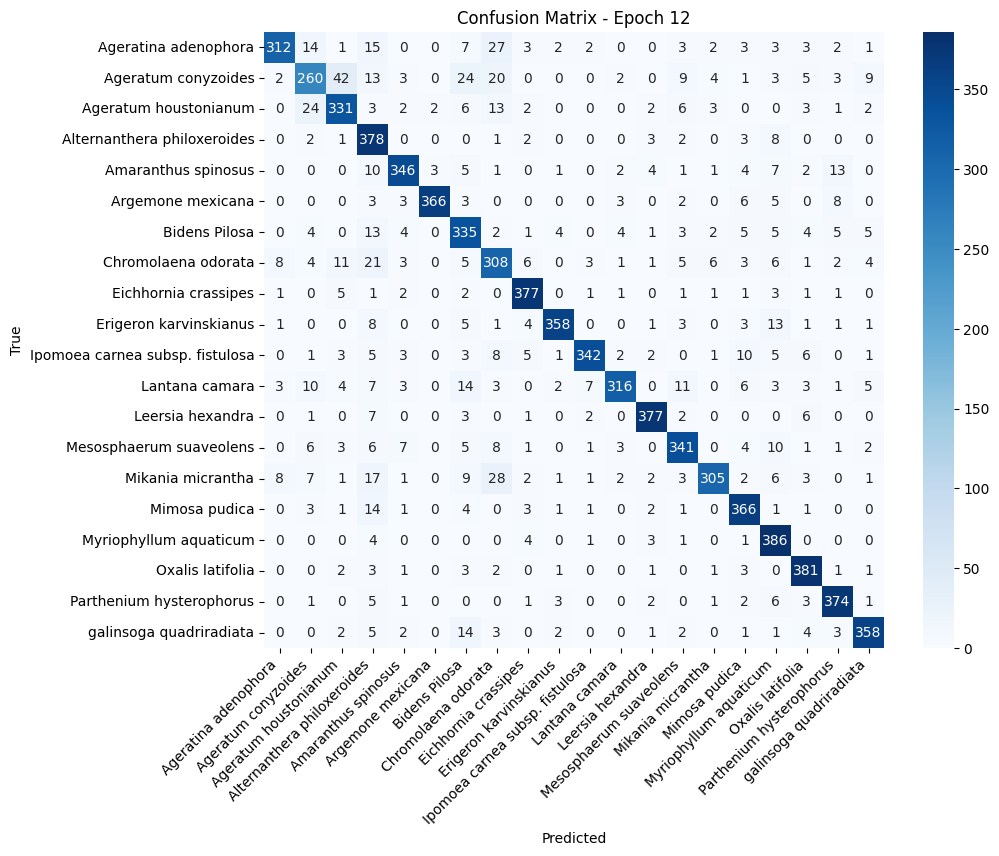


Epoch 13/50
------------------------------


Train Loss: 0.4905 Acc: 0.8460 Precision: 0.8452 Recall: 0.8460 F1: 0.8453


Val Loss: 0.3956 Acc: 0.8791 Precision: 0.8810 Recall: 0.8791 F1: 0.8790
Top-5 Accuracy: 0.9808

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.90      0.82      0.86       400
            Ageratum conyzoides       0.70      0.71      0.70       400
          Ageratum houstonianum       0.82      0.79      0.80       400
    Alternanthera philoxeroides       0.85      0.94      0.89       400
            Amaranthus spinosus       0.93      0.90      0.92       400
              Argemone mexicana       0.98      0.96      0.97       399
                  Bidens Pilosa       0.85      0.78      0.81       397
            Chromolaena odorata       0.81      0.79      0.80       398
           Eichhornia crassipes       0.92      0.94      0.93       398
         Erigeron karvinskianus       0.96      0.91      0.93       400
Ipomoea carnea subsp. fistulosa       0.84      0.93      0.89       3

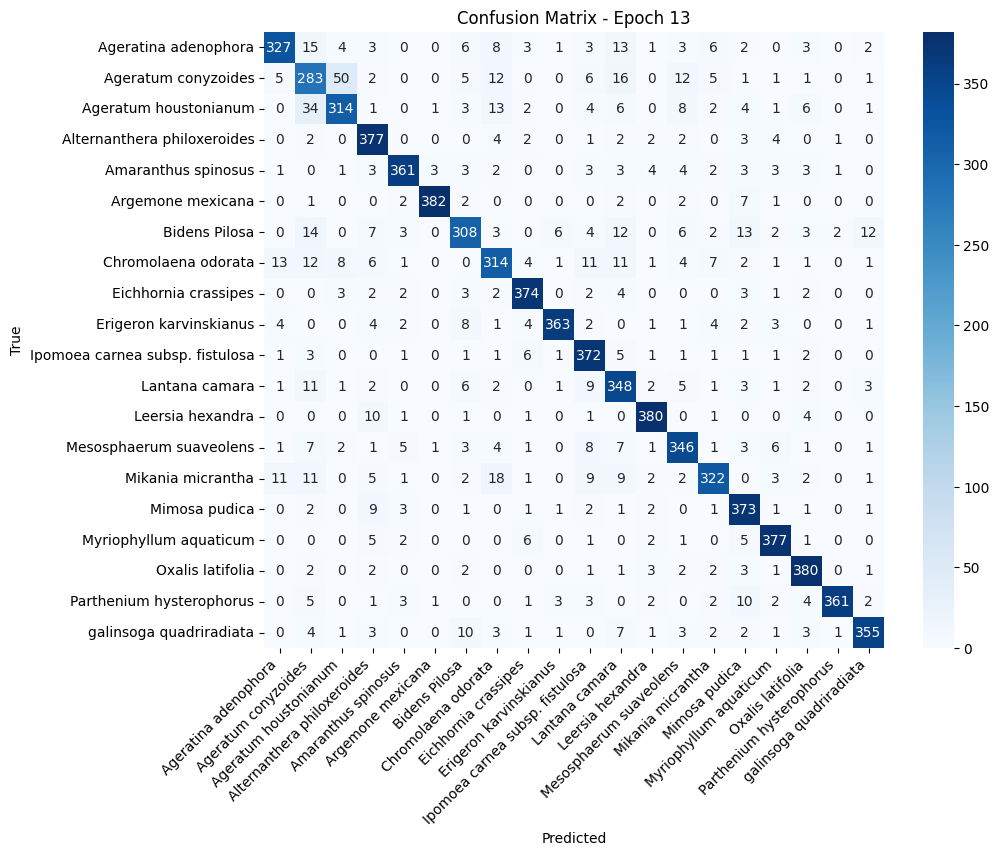


Epoch 14/50
------------------------------


Train Loss: 0.4728 Acc: 0.8531 Precision: 0.8519 Recall: 0.8530 F1: 0.8523


Val Loss: 0.4415 Acc: 0.8648 Precision: 0.8713 Recall: 0.8648 F1: 0.8647
Top-5 Accuracy: 0.9788

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.97      0.75      0.85       400
            Ageratum conyzoides       0.70      0.73      0.71       400
          Ageratum houstonianum       0.80      0.81      0.80       400
    Alternanthera philoxeroides       0.90      0.86      0.88       400
            Amaranthus spinosus       0.92      0.82      0.87       400
              Argemone mexicana       0.98      0.96      0.97       399
                  Bidens Pilosa       0.81      0.79      0.80       397
            Chromolaena odorata       0.85      0.70      0.77       398
           Eichhornia crassipes       0.96      0.93      0.95       398
         Erigeron karvinskianus       0.93      0.92      0.92       400
Ipomoea carnea subsp. fistulosa       0.83      0.91      0.87       3

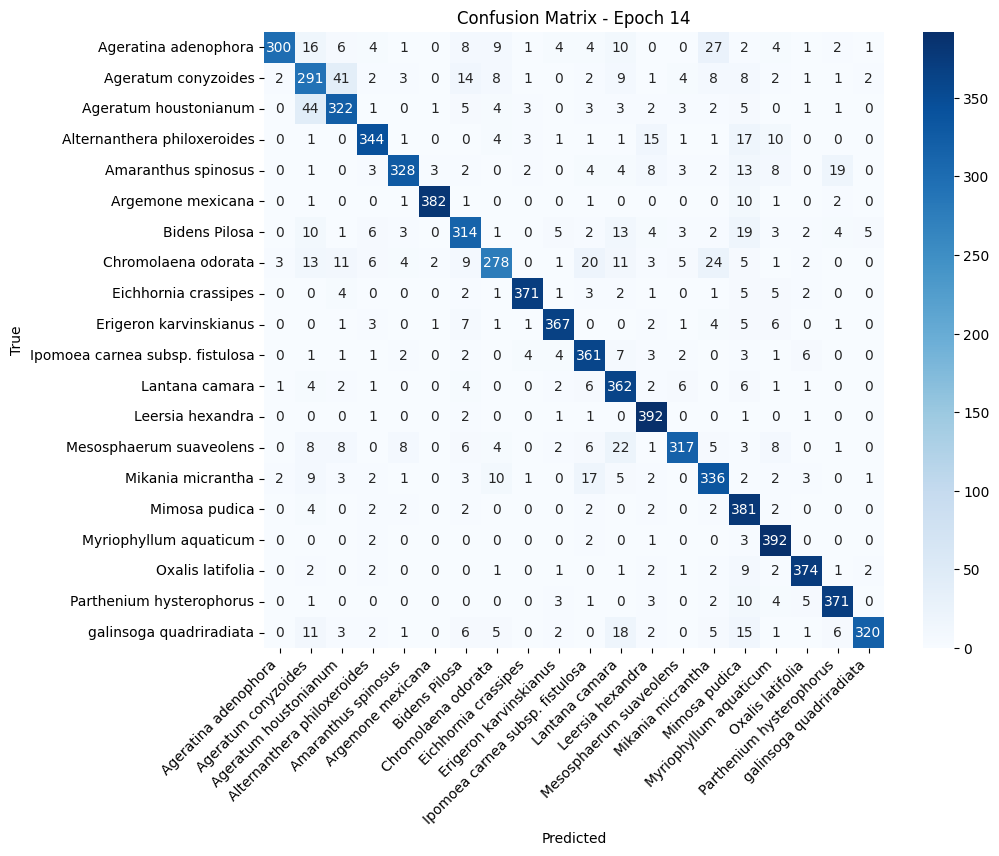


Epoch 15/50
------------------------------


Train Loss: 0.4651 Acc: 0.8535 Precision: 0.8524 Recall: 0.8534 F1: 0.8527


Val Loss: 0.3880 Acc: 0.8865 Precision: 0.8876 Recall: 0.8865 F1: 0.8864
Top-5 Accuracy: 0.9801

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.84      0.85      0.85       400
            Ageratum conyzoides       0.76      0.71      0.74       400
          Ageratum houstonianum       0.82      0.79      0.80       400
    Alternanthera philoxeroides       0.84      0.94      0.89       400
            Amaranthus spinosus       0.96      0.86      0.91       400
              Argemone mexicana       0.97      0.95      0.96       399
                  Bidens Pilosa       0.80      0.85      0.82       397
            Chromolaena odorata       0.77      0.82      0.79       398
           Eichhornia crassipes       0.93      0.96      0.94       398
         Erigeron karvinskianus       0.92      0.93      0.93       400
Ipomoea carnea subsp. fistulosa       0.92      0.87      0.90       3

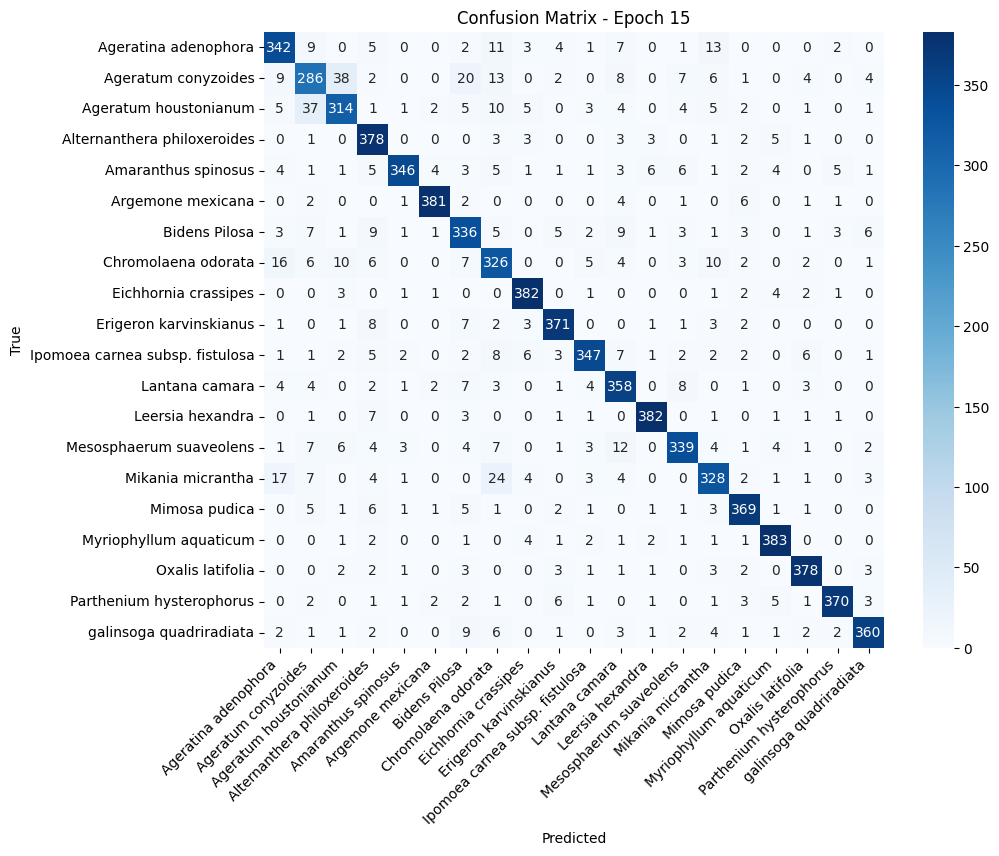


Epoch 16/50
------------------------------


Train Loss: 0.4522 Acc: 0.8544 Precision: 0.8534 Recall: 0.8544 F1: 0.8537


Val Loss: 0.4080 Acc: 0.8794 Precision: 0.8826 Recall: 0.8793 F1: 0.8790
Top-5 Accuracy: 0.9795

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.90      0.85      0.88       400
            Ageratum conyzoides       0.71      0.76      0.73       400
          Ageratum houstonianum       0.88      0.72      0.79       400
    Alternanthera philoxeroides       0.77      0.94      0.85       400
            Amaranthus spinosus       0.95      0.87      0.91       400
              Argemone mexicana       0.98      0.95      0.97       399
                  Bidens Pilosa       0.86      0.74      0.79       397
            Chromolaena odorata       0.78      0.80      0.79       398
           Eichhornia crassipes       0.95      0.95      0.95       398
         Erigeron karvinskianus       0.97      0.91      0.94       400
Ipomoea carnea subsp. fistulosa       0.91      0.87      0.89       3

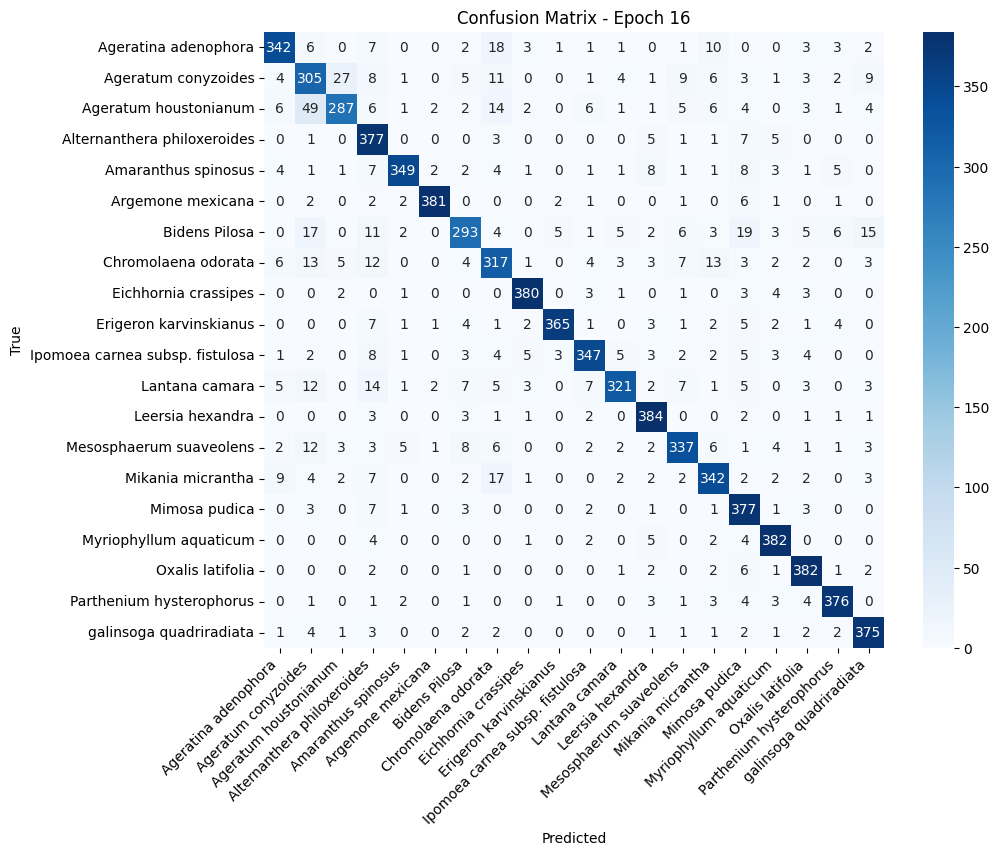


Epoch 17/50
------------------------------


Train Loss: 0.4355 Acc: 0.8621 Precision: 0.8612 Recall: 0.8621 F1: 0.8615


Val Loss: 0.4047 Acc: 0.8799 Precision: 0.8835 Recall: 0.8799 F1: 0.8790
Top-5 Accuracy: 0.9820

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.88      0.85      0.87       400
            Ageratum conyzoides       0.84      0.60      0.70       400
          Ageratum houstonianum       0.77      0.81      0.79       400
    Alternanthera philoxeroides       0.81      0.95      0.88       400
            Amaranthus spinosus       0.95      0.88      0.91       400
              Argemone mexicana       0.98      0.94      0.96       399
                  Bidens Pilosa       0.88      0.76      0.82       397
            Chromolaena odorata       0.70      0.86      0.78       398
           Eichhornia crassipes       0.94      0.96      0.95       398
         Erigeron karvinskianus       0.92      0.93      0.93       400
Ipomoea carnea subsp. fistulosa       0.94      0.89      0.92       3

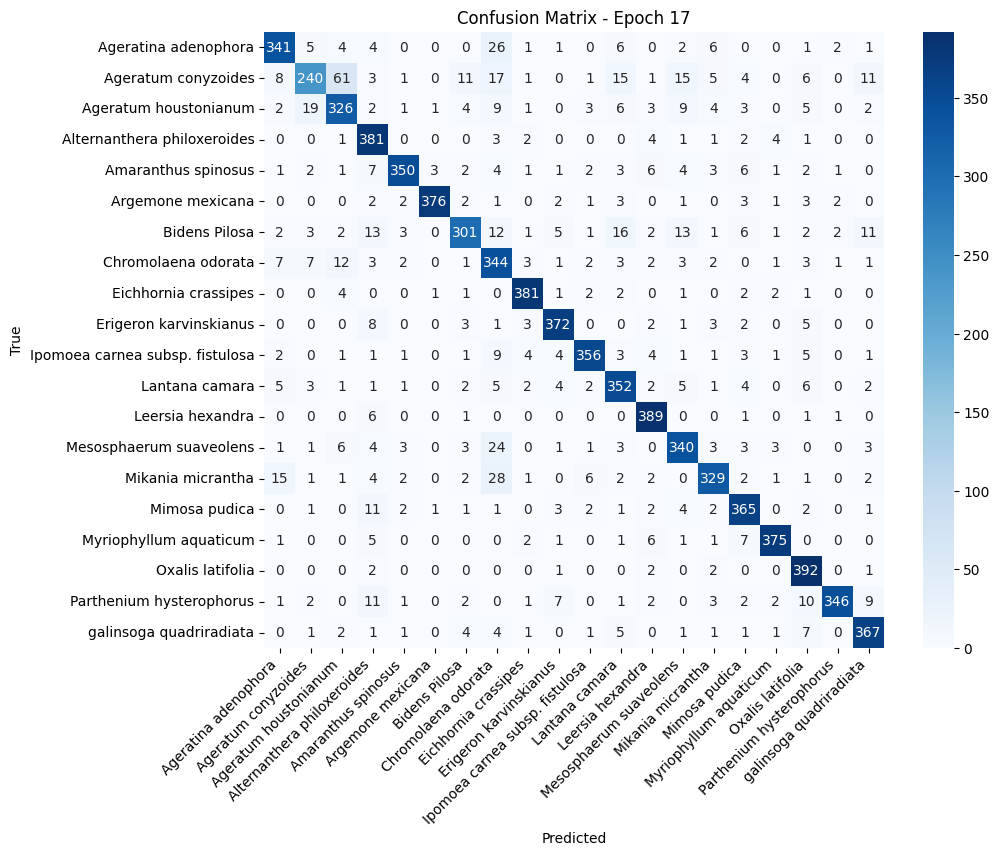


Epoch 18/50
------------------------------


Train Loss: 0.4301 Acc: 0.8643 Precision: 0.8634 Recall: 0.8643 F1: 0.8636


Val Loss: 0.3733 Acc: 0.8905 Precision: 0.8910 Recall: 0.8905 F1: 0.8900
Top-5 Accuracy: 0.9815

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.89      0.87      0.88       400
            Ageratum conyzoides       0.75      0.72      0.74       400
          Ageratum houstonianum       0.84      0.79      0.81       400
    Alternanthera philoxeroides       0.88      0.93      0.90       400
            Amaranthus spinosus       0.94      0.88      0.91       400
              Argemone mexicana       0.98      0.95      0.96       399
                  Bidens Pilosa       0.83      0.81      0.82       397
            Chromolaena odorata       0.79      0.80      0.80       398
           Eichhornia crassipes       0.92      0.94      0.93       398
         Erigeron karvinskianus       0.89      0.95      0.92       400
Ipomoea carnea subsp. fistulosa       0.94      0.90      0.92       3

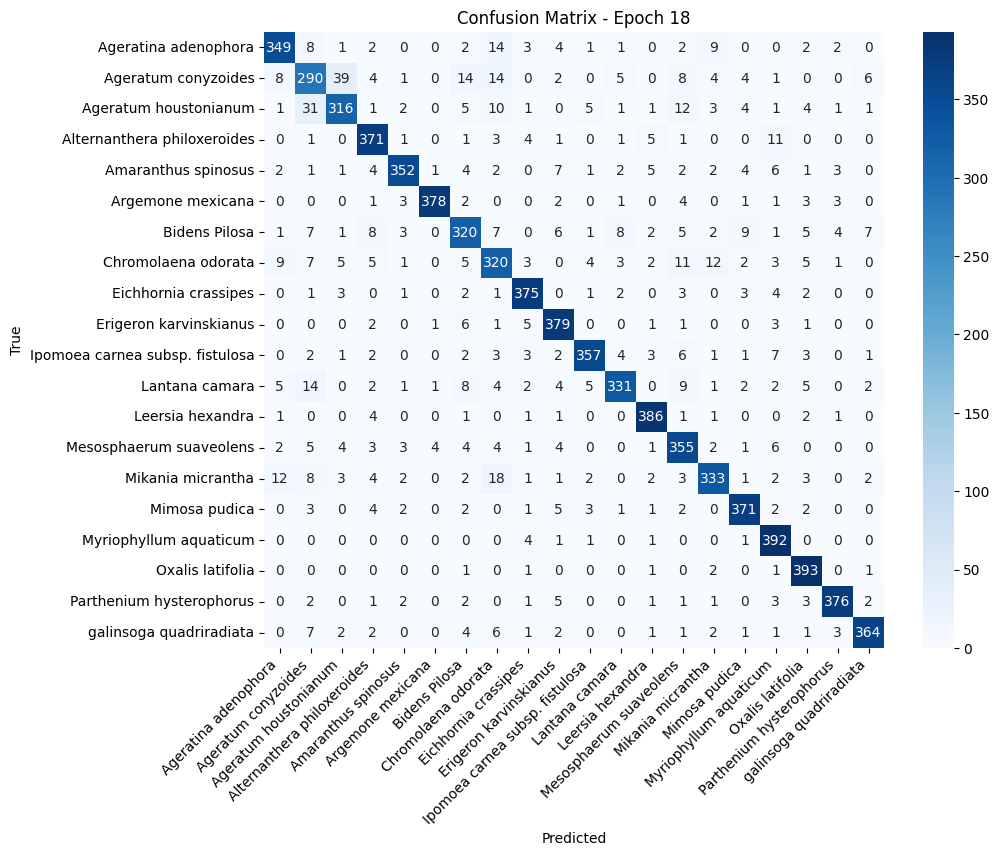


Epoch 19/50
------------------------------


Train Loss: 0.4274 Acc: 0.8647 Precision: 0.8638 Recall: 0.8647 F1: 0.8641


Val Loss: 0.3488 Acc: 0.8940 Precision: 0.8940 Recall: 0.8940 F1: 0.8935
Top-5 Accuracy: 0.9848

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.87      0.84      0.85       400
            Ageratum conyzoides       0.76      0.70      0.73       400
          Ageratum houstonianum       0.81      0.82      0.81       400
    Alternanthera philoxeroides       0.89      0.93      0.91       400
            Amaranthus spinosus       0.94      0.89      0.92       400
              Argemone mexicana       0.95      0.97      0.96       399
                  Bidens Pilosa       0.84      0.85      0.84       397
            Chromolaena odorata       0.84      0.81      0.82       398
           Eichhornia crassipes       0.97      0.94      0.95       398
         Erigeron karvinskianus       0.93      0.95      0.94       400
Ipomoea carnea subsp. fistulosa       0.92      0.88      0.90       3

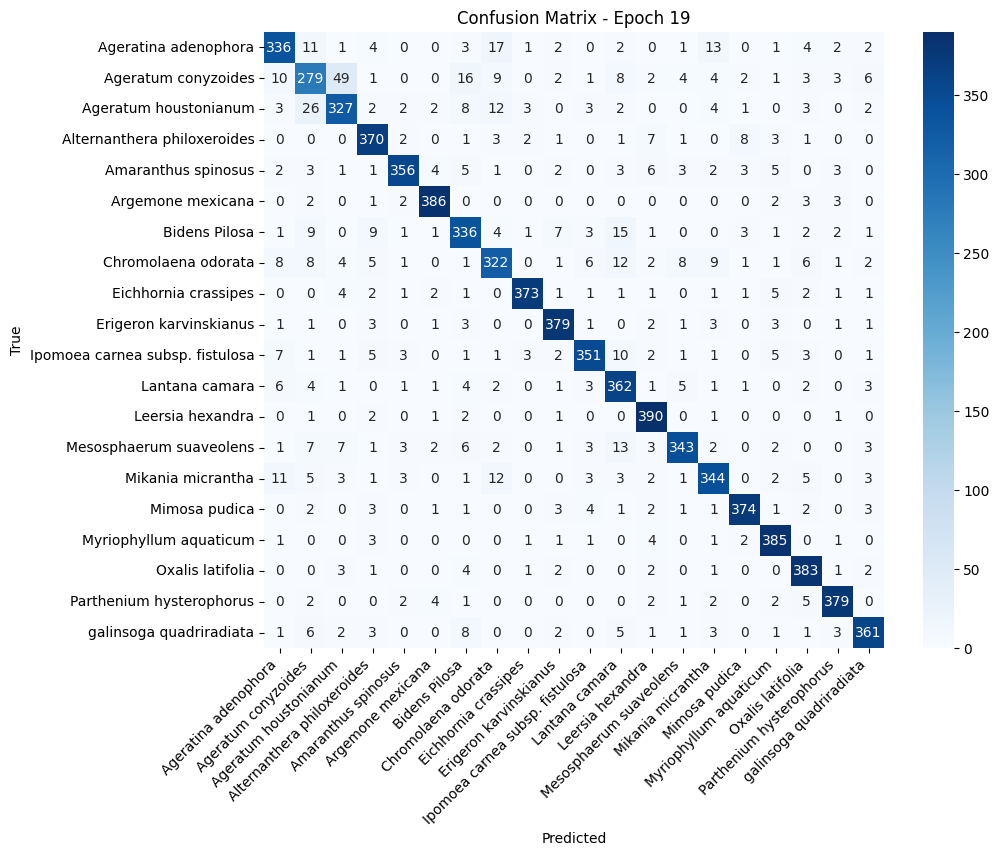


Epoch 20/50
------------------------------


Train Loss: 0.4144 Acc: 0.8709 Precision: 0.8703 Recall: 0.8709 F1: 0.8704


Val Loss: 0.3722 Acc: 0.8882 Precision: 0.8952 Recall: 0.8882 F1: 0.8895
Top-5 Accuracy: 0.9837

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.90      0.84      0.87       400
            Ageratum conyzoides       0.69      0.79      0.74       400
          Ageratum houstonianum       0.92      0.75      0.83       400
    Alternanthera philoxeroides       0.76      0.96      0.85       400
            Amaranthus spinosus       0.96      0.89      0.92       400
              Argemone mexicana       0.99      0.96      0.98       399
                  Bidens Pilosa       0.73      0.90      0.80       397
            Chromolaena odorata       0.81      0.78      0.79       398
           Eichhornia crassipes       0.99      0.94      0.96       398
         Erigeron karvinskianus       0.93      0.91      0.92       400
Ipomoea carnea subsp. fistulosa       0.93      0.87      0.90       3

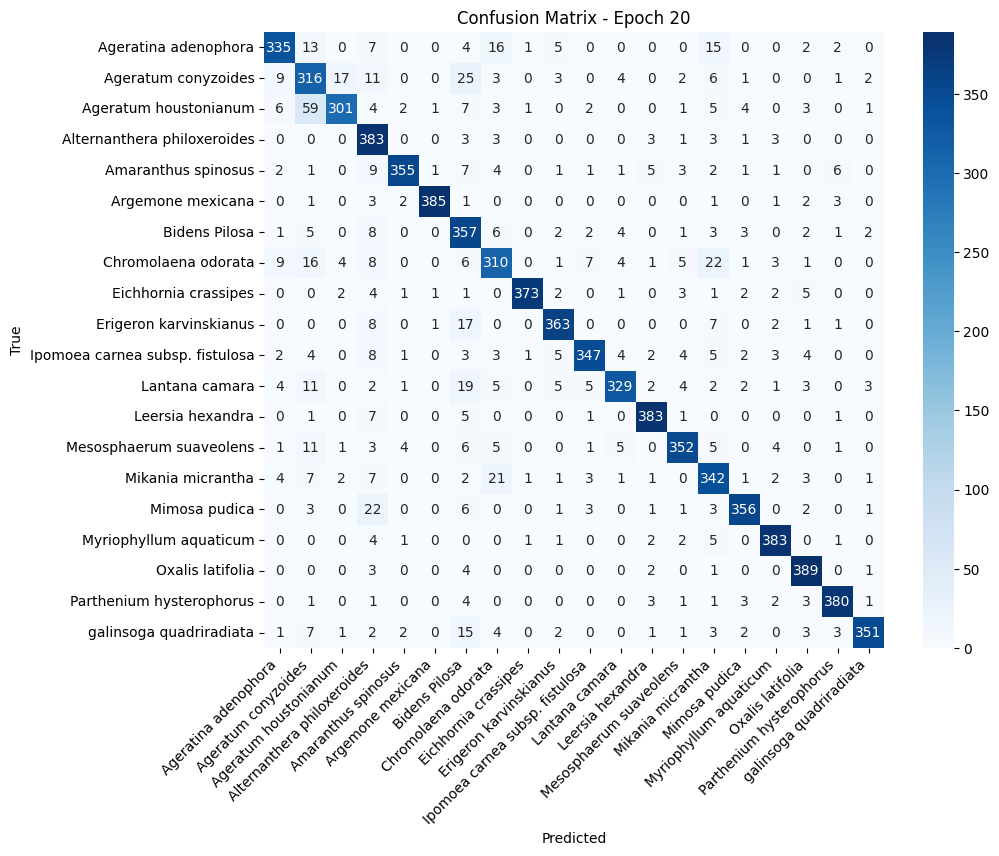


Epoch 21/50
------------------------------


Train Loss: 0.4136 Acc: 0.8695 Precision: 0.8688 Recall: 0.8695 F1: 0.8690


Val Loss: 0.3815 Acc: 0.8849 Precision: 0.8883 Recall: 0.8849 F1: 0.8853
Top-5 Accuracy: 0.9825

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.87      0.86      0.87       400
            Ageratum conyzoides       0.71      0.74      0.72       400
          Ageratum houstonianum       0.86      0.76      0.80       400
    Alternanthera philoxeroides       0.78      0.93      0.85       400
            Amaranthus spinosus       0.96      0.89      0.92       400
              Argemone mexicana       0.97      0.94      0.95       399
                  Bidens Pilosa       0.81      0.84      0.82       397
            Chromolaena odorata       0.77      0.83      0.80       398
           Eichhornia crassipes       0.98      0.93      0.96       398
         Erigeron karvinskianus       0.88      0.94      0.91       400
Ipomoea carnea subsp. fistulosa       0.93      0.90      0.92       3

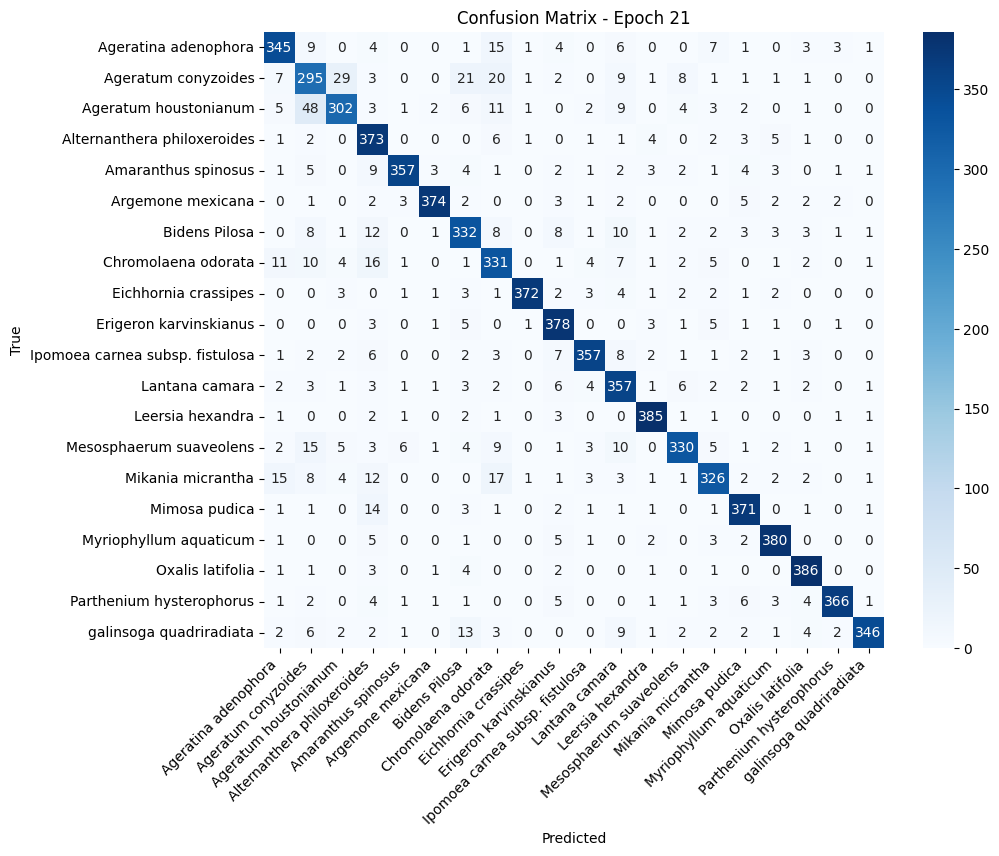


Epoch 22/50
------------------------------


Train Loss: 0.4028 Acc: 0.8752 Precision: 0.8745 Recall: 0.8752 F1: 0.8747


Val Loss: 0.3872 Acc: 0.8869 Precision: 0.8891 Recall: 0.8868 F1: 0.8864
Top-5 Accuracy: 0.9800

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.79      0.89      0.84       400
            Ageratum conyzoides       0.77      0.71      0.74       400
          Ageratum houstonianum       0.83      0.81      0.82       400
    Alternanthera philoxeroides       0.87      0.91      0.89       400
            Amaranthus spinosus       0.97      0.89      0.93       400
              Argemone mexicana       0.98      0.95      0.97       399
                  Bidens Pilosa       0.86      0.79      0.82       397
            Chromolaena odorata       0.90      0.73      0.80       398
           Eichhornia crassipes       0.98      0.93      0.95       398
         Erigeron karvinskianus       0.91      0.94      0.92       400
Ipomoea carnea subsp. fistulosa       0.89      0.92      0.90       3

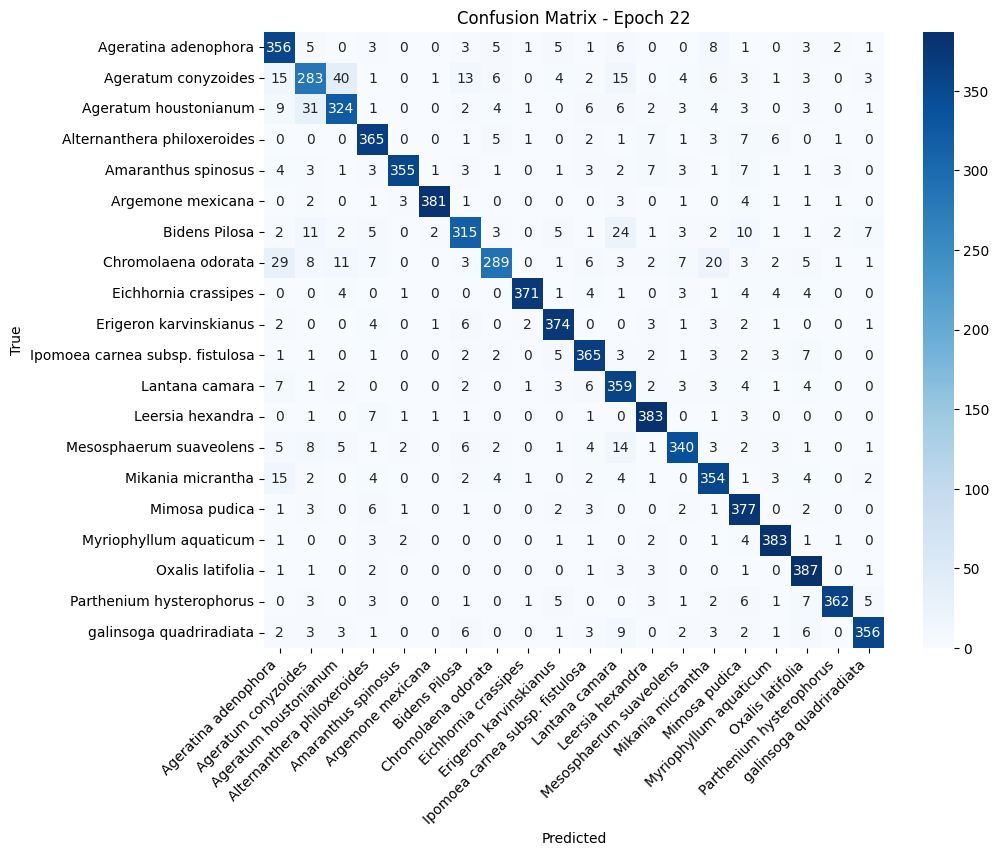


Epoch 23/50
------------------------------


Train Loss: 0.3970 Acc: 0.8747 Precision: 0.8741 Recall: 0.8747 F1: 0.8743


Val Loss: 0.3678 Acc: 0.8931 Precision: 0.8946 Recall: 0.8931 F1: 0.8923
Top-5 Accuracy: 0.9826

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.86      0.90      0.88       400
            Ageratum conyzoides       0.84      0.67      0.74       400
          Ageratum houstonianum       0.83      0.83      0.83       400
    Alternanthera philoxeroides       0.87      0.92      0.89       400
            Amaranthus spinosus       0.95      0.89      0.92       400
              Argemone mexicana       0.97      0.97      0.97       399
                  Bidens Pilosa       0.77      0.88      0.82       397
            Chromolaena odorata       0.89      0.76      0.82       398
           Eichhornia crassipes       0.95      0.96      0.96       398
         Erigeron karvinskianus       0.94      0.92      0.93       400
Ipomoea carnea subsp. fistulosa       0.91      0.90      0.91       3

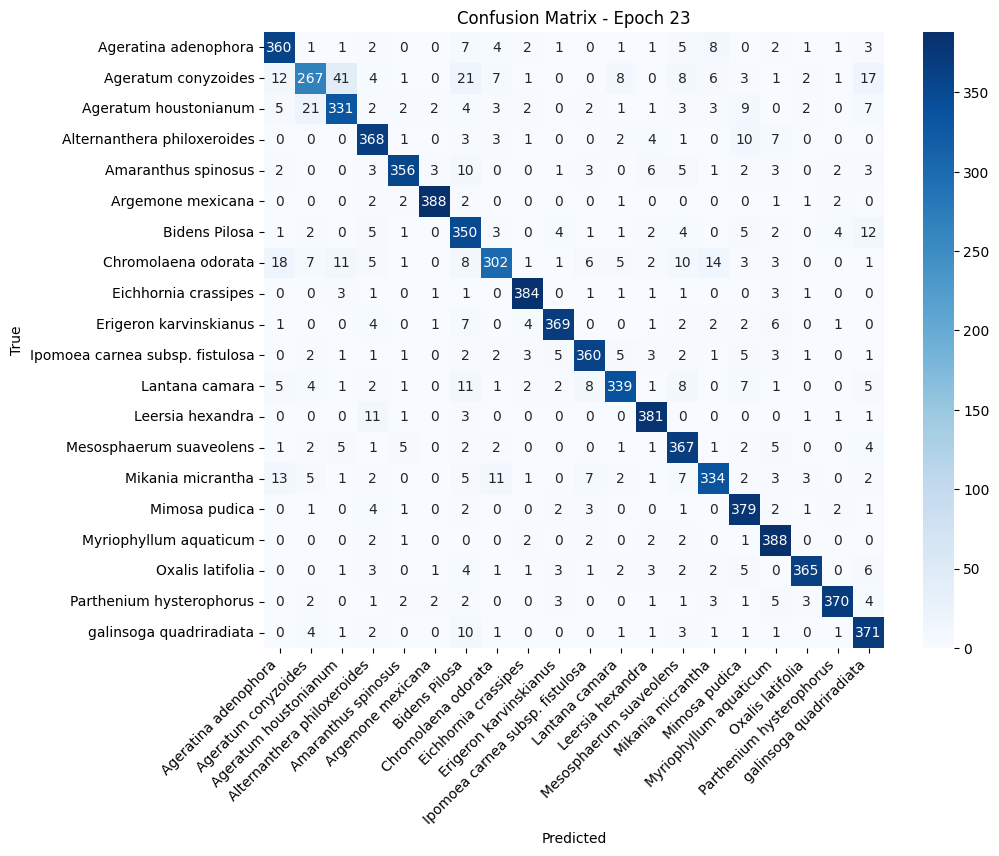


Epoch 24/50
------------------------------


Train Loss: 0.3855 Acc: 0.8800 Precision: 0.8794 Recall: 0.8800 F1: 0.8796


Val Loss: 0.4027 Acc: 0.8835 Precision: 0.8922 Recall: 0.8834 F1: 0.8847
Top-5 Accuracy: 0.9816

Classification Report (Val):
                                 precision    recall  f1-score   support

           Ageratina adenophora       0.92      0.82      0.87       400
            Ageratum conyzoides       0.65      0.79      0.72       400
          Ageratum houstonianum       0.79      0.85      0.82       400
    Alternanthera philoxeroides       0.68      0.96      0.80       400
            Amaranthus spinosus       0.96      0.88      0.92       400
              Argemone mexicana       0.92      0.98      0.95       399
                  Bidens Pilosa       0.89      0.83      0.86       397
            Chromolaena odorata       0.90      0.68      0.77       398
           Eichhornia crassipes       0.97      0.93      0.95       398
         Erigeron karvinskianus       0.94      0.93      0.94       400
Ipomoea carnea subsp. fistulosa       0.91      0.90      0.90       3

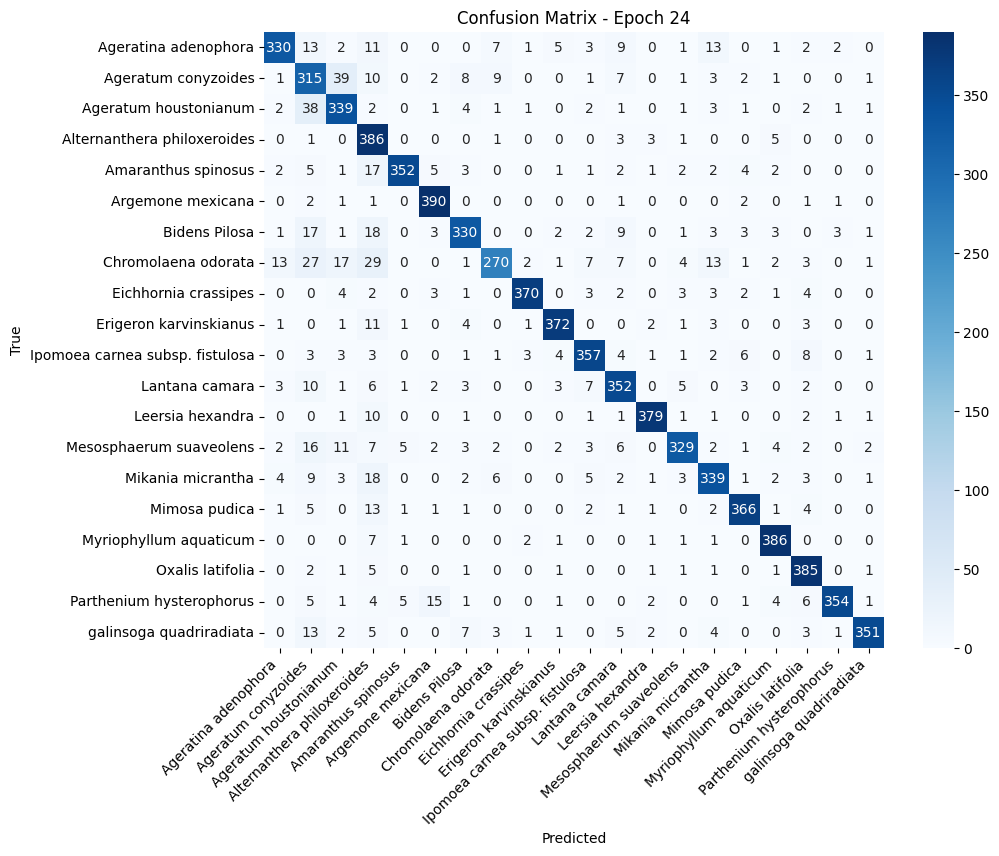

⏹️ Early stopping triggered.


In [ ]:
model, history = train_model(model, dataloaders, criterion, optimizer, num_epochs=50, patience=5)
torch.save(model.state_dict(), 'densenet121_plant_classifier_final.pth')
